# 04 - Feature Relationships with Risk

**Project:** German Credit Risk
**Dataset:** `data/german_credit_data.csv`
**Author:** Divya Akbari

**Goal of this notebook**
Perform statistical analysis to find out which features are related to the target variable `Risk`, how strong each
relationship is, and which features still matter when they are looked at together.

| Step | Method |
|---|---|
| Categorical features vs Risk | Chi-square test of independence and Cramer's V (strength) |
| Numerical features vs Risk | Mann-Whitney U test and rank-biserial correlation (strength) |
| Many tests at once | Holm correction of p-values |
| Ranking of features | Information Value (IV), a standard measure in credit scoring |
| All features together | Logistic regression with odds ratios |

A result is called **significant** when its p-value is below **0.05**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', None)   # show full text in tables

## 1. Prepare the data

In [2]:
df = pd.read_csv('data/german_credit_data.csv')
df = df.drop(columns=['Unnamed: 0'])            # row number only

# Target as a number: 1 = bad risk, 0 = good risk
df['bad'] = (df['Risk'] == 'bad').astype(int)

# Missing account values are kept as their own group (they carry information)
df['Saving accounts'] = df['Saving accounts'].fillna('missing')
df['Checking account'] = df['Checking account'].fillna('missing')

# Job is a skill level, so it is treated as a category
df['Job'] = df['Job'].astype(str)

# Three purposes have fewer than 30 customers, so they are combined into 'other'
df['Purpose group'] = df['Purpose'].replace({'repairs': 'other', 'domestic appliances': 'other', 'vacation/others': 'other'})

print(df.shape)
print('Bad rate overall:', round(df['bad'].mean() * 100, 1), '%')
df['Purpose group'].value_counts()

(1000, 12)
Bad rate overall: 30.0 %


Purpose group
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
other                   46
Name: count, dtype: int64

## 2. Categorical features vs Risk

**Chi-square test:** checks whether the bad rate is the same in every group of a feature.
A small p-value means the feature and Risk are related.

**Cramer's V:** shows how *strong* the relationship is, from 0 (none) to 1 (perfect).
As a guide: below 0.10 = negligible, 0.10 to 0.20 = weak, 0.20 to 0.30 = moderate, above 0.30 = strong.

In [3]:
cat_features = ['Checking account', 'Saving accounts', 'Housing', 'Purpose group', 'Sex', 'Job']

def strength(v):
    if v < 0.10: return 'negligible'
    if v < 0.20: return 'weak'
    if v < 0.30: return 'moderate'
    return 'strong'

rows = []
for col in cat_features:
    table = pd.crosstab(df[col], df['Risk'])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))
    rows.append([col, round(chi2, 2), dof, p, round(cramers_v, 3), strength(cramers_v), int((expected < 5).sum())])

cat_results = pd.DataFrame(rows, columns=['Feature', 'Chi-square', 'df', 'p-value', "Cramer's V", 'Strength', 'Cells with expected < 5'])
cat_results.sort_values("Cramer's V", ascending=False)

,Feature,Chi-square,df,p-value,Cramer's V,Strength,Cells with expected < 5
0,Checking account,123.72,3,1.218902e-26,0.352,strong,0
1,Saving accounts,36.10,4,2.761214e-07,0.190,weak,0
2,Housing,18.20,2,1.116747e-04,0.135,weak,0
3,Purpose group,13.44,5,1.961331e-02,0.116,weak,0
4,Sex,5.35,1,2.073991e-02,0.073,negligible,0
5,Job,1.89,3,5.965816e-01,0.043,negligible,0


All expected counts are 5 or more, so the chi-square test is valid for every feature.

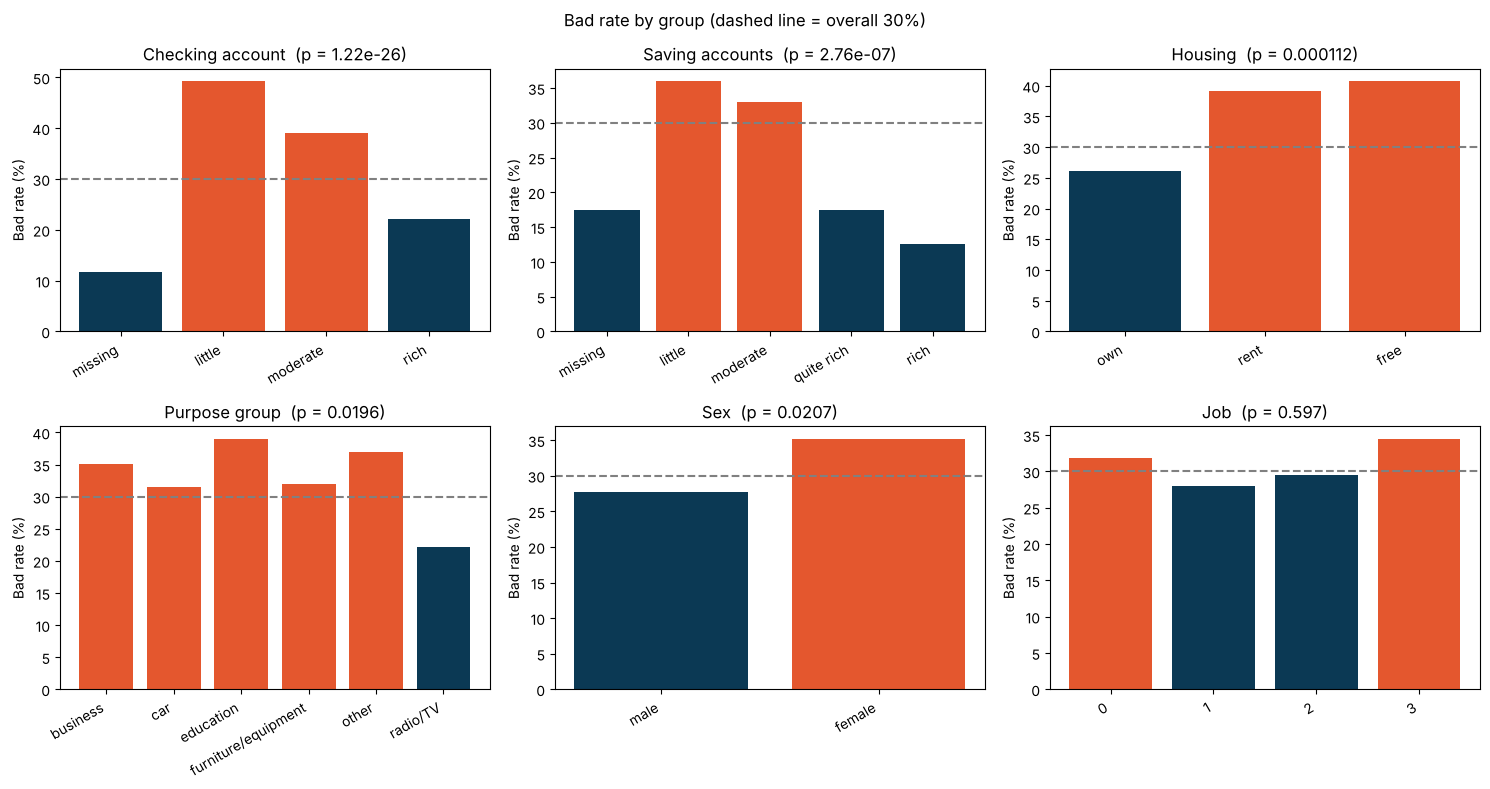

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
order = {'Checking account': ['missing', 'little', 'moderate', 'rich'],
         'Saving accounts': ['missing', 'little', 'moderate', 'quite rich', 'rich'],
         'Housing': ['own', 'rent', 'free'], 'Sex': ['male', 'female'], 'Job': ['0', '1', '2', '3']}
for ax, col in zip(axes.flatten(), cat_features):
    rate = df.groupby(col)['bad'].mean() * 100
    if col in order:
        rate = rate.loc[order[col]]
    ax.bar(rate.index, rate.values, color=['#E4572E' if v > 30 else '#0B3954' for v in rate.values])
    ax.axhline(30, color='grey', linestyle='--')
    p = cat_results.set_index('Feature').loc[col, 'p-value']
    ax.set_title(f'{col}  (p = {p:.3g})')
    ax.set_ylabel('Bad rate (%)')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.suptitle('Bad rate by group (dashed line = overall 30%)')
plt.tight_layout()
plt.show()

### 2.1 Do account balances show a trend?
The Cochran-Armitage trend test checks whether risk goes steadily **down** as the balance goes up.
Only customers with a recorded balance are used here.

In [5]:
def trend_test(col, levels):
    data = df[df[col].isin(levels)]
    score = data[col].map({level: i for i, level in enumerate(levels)})
    y = data['bad']
    t = ((score - score.mean()) * y).sum()
    variance = y.mean() * (1 - y.mean()) * ((score - score.mean()) ** 2).sum()
    z = t / np.sqrt(variance)
    p = 2 * stats.norm.sf(abs(z))
    return round(z, 2), p

trend = pd.DataFrame([
    ['Saving accounts', 'little < moderate < quite rich < rich', *trend_test('Saving accounts', ['little', 'moderate', 'quite rich', 'rich'])],
    ['Checking account', 'little < moderate < rich', *trend_test('Checking account', ['little', 'moderate', 'rich'])],
], columns=['Feature', 'Order tested', 'z', 'p-value'])
trend

,Feature,Order tested,z,p-value
0,Saving accounts,little < moderate < quite rich < rich,-4.15,0.000034
1,Checking account,little < moderate < rich,-4.07,0.000048


A negative z means risk falls as the balance rises. Both trends are significant.

### 2.2 Do missing account values carry information?
Customers with a missing value are compared with customers whose balance is recorded.

In [6]:
rows = []
for col in ['Checking account', 'Saving accounts']:
    is_missing = df[col] == 'missing'
    chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(is_missing, df['Risk']))
    rows.append([col, is_missing.sum(), round(df.loc[is_missing, 'bad'].mean() * 100, 1),
                 round(df.loc[~is_missing, 'bad'].mean() * 100, 1), round(chi2, 2), p])
missing_test = pd.DataFrame(rows, columns=['Feature', 'Missing customers', 'Bad rate missing (%)', 'Bad rate recorded (%)', 'Chi-square', 'p-value'])
missing_test

,Feature,Missing customers,Bad rate missing (%),Bad rate recorded (%),Chi-square,p-value
0,Checking account,394,11.7,41.9,102.53,4.249243e-24
1,Saving accounts,183,17.5,32.8,15.98,6.398184e-05


## 3. Numerical features vs Risk

**Mann-Whitney U test:** compares good-risk and bad-risk customers without assuming a normal distribution
(Age, Credit amount and Duration are all skewed).

**Rank-biserial correlation:** shows the size and direction of the difference, from -1 to +1.
A positive value means bad-risk customers tend to have **higher** values.

In [7]:
num_features = ['Duration', 'Credit amount', 'Age']

rows = []
for col in num_features:
    good = df.loc[df['bad'] == 0, col]
    bad = df.loc[df['bad'] == 1, col]
    u, p = stats.mannwhitneyu(bad, good, alternative='two-sided')
    rank_biserial = 2 * u / (len(good) * len(bad)) - 1
    rows.append([col, good.median(), bad.median(), round(u, 1), p, round(rank_biserial, 3)])

num_results = pd.DataFrame(rows, columns=['Feature', 'Median (good)', 'Median (bad)', 'U statistic', 'p-value', 'Rank-biserial r'])
num_results

,Feature,Median (good),Median (bad),U statistic,p-value,Rank-biserial r
0,Duration,18.0,24.0,132004.5,7.981666e-11,0.257
1,Credit amount,2244.0,2574.5,116520.0,5.917609e-03,0.110
2,Age,34.0,31.0,90167.0,3.912774e-04,-0.141


### 3.1 Bad rate by band
Grouping the numbers into bands shows the *shape* of each relationship.

In [8]:
df['Duration band'] = pd.cut(df['Duration'], [0, 12, 24, 36, 100], labels=['up to 12', '13-24', '25-36', 'over 36'])
df['Age band'] = pd.cut(df['Age'], [18, 25, 35, 45, 55, 100], labels=['19-25', '26-35', '36-45', '46-55', '56+'])
df['Credit band'] = pd.qcut(df['Credit amount'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])

for band in ['Duration band', 'Credit band', 'Age band']:
    summary = df.groupby(band, observed=True).agg(customers=('bad', 'size'), bad=('bad', 'sum'), bad_rate=('bad', 'mean'))
    summary['bad_rate'] = (summary['bad_rate'] * 100).round(1)
    print(band)
    print(summary)
    print()

Duration band
               customers  bad  bad_rate
Duration band                          
up to 12             359   76      21.2
13-24                411  122      29.7
25-36                143   57      39.9
over 36               87   45      51.7

Credit band
              customers  bad  bad_rate
Credit band                           
Q1 (lowest)         250   77      30.8
Q2                  250   62      24.8
Q3                  250   56      22.4
Q4 (highest)        250  105      42.0

Age band
          customers  bad  bad_rate
Age band                          
19-25           190   80      42.1
26-35           398  118      29.6
36-45           226   55      24.3
46-55           115   28      24.3
56+              71   19      26.8



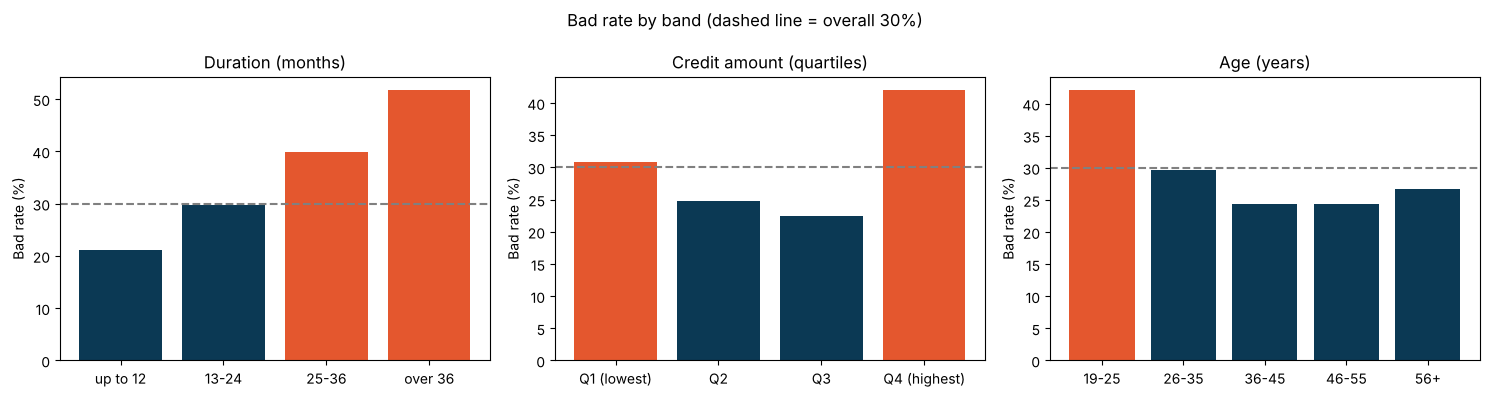

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, band, title in zip(axes, ['Duration band', 'Credit band', 'Age band'], ['Duration (months)', 'Credit amount (quartiles)', 'Age (years)']):
    rate = df.groupby(band, observed=True)['bad'].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=['#E4572E' if v > 30 else '#0B3954' for v in rate.values])
    ax.axhline(30, color='grey', linestyle='--')
    ax.set_title(title)
    ax.set_ylabel('Bad rate (%)')
plt.suptitle('Bad rate by band (dashed line = overall 30%)')
plt.tight_layout()
plt.show()

**Shapes of the relationships**
- **Duration:** risk rises steadily with loan length, from 21.2% (up to 12 months) to 51.7% (over 36 months).
- **Credit amount:** U-shaped. The largest loans are riskiest (42.0%), but the smallest loans (30.8%) are riskier than mid-sized ones (22.4% to 24.8%).
- **Age:** the youngest group (19 to 25) is riskiest (42.1%); after age 35 risk levels off at about 24% to 27%.

## 4. All tests together, with Holm correction
Running many tests increases the chance of a false positive. The Holm correction adjusts the p-values to allow for this.

In [10]:
all_tests = pd.concat([
    cat_results[['Feature', 'p-value', "Cramer's V"]].rename(columns={"Cramer's V": 'Effect size'}).assign(Test='Chi-square', Measure="Cramer's V"),
    num_results[['Feature', 'p-value', 'Rank-biserial r']].rename(columns={'Rank-biserial r': 'Effect size'}).assign(Test='Mann-Whitney U', Measure='Rank-biserial r'),
], ignore_index=True)

all_tests['Holm p-value'] = multipletests(all_tests['p-value'], method='holm')[1]
all_tests['Significant after correction'] = np.where(all_tests['Holm p-value'] < 0.05, 'Yes', 'No')
all_tests = all_tests[['Feature', 'Test', 'p-value', 'Holm p-value', 'Measure', 'Effect size', 'Significant after correction']]
all_tests.sort_values('p-value')

,Feature,Test,p-value,Holm p-value,Measure,Effect size,Significant after correction
0,Checking account,Chi-square,1.218902e-26,1.097012e-25,Cramer's V,0.352,Yes
6,Duration,Mann-Whitney U,7.981666e-11,6.385332e-10,Rank-biserial r,0.257,Yes
1,Saving accounts,Chi-square,2.761214e-07,1.932850e-06,Cramer's V,0.190,Yes
2,Housing,Chi-square,1.116747e-04,6.700479e-04,Cramer's V,0.135,Yes
8,Age,Mann-Whitney U,3.912774e-04,1.956387e-03,Rank-biserial r,-0.141,Yes
7,Credit amount,Mann-Whitney U,5.917609e-03,2.367044e-02,Rank-biserial r,0.110,Yes
3,Purpose group,Chi-square,1.961331e-02,5.883992e-02,Cramer's V,0.116,No
4,Sex,Chi-square,2.073991e-02,5.883992e-02,Cramer's V,0.073,No
5,Job,Chi-square,5.965816e-01,5.965816e-01,Cramer's V,0.043,No


Seven of the nine features are significant after correction. **Purpose** and **Sex** have raw p-values near 0.02
but are **not** significant once the correction is applied. **Job** is not related to risk at all.

## 5. Information Value (IV)
IV is the standard way to rank features in credit scoring. Guide: below 0.02 = not useful, 0.02 to 0.1 = weak,
0.1 to 0.3 = medium, above 0.3 = strong. Numerical features use the bands from Section 3.

In [11]:
def information_value(col):
    table = pd.crosstab(df[col], df['bad'])
    good_share = table[0] / table[0].sum()
    bad_share = table[1] / table[1].sum()
    woe = np.log(good_share / bad_share)          # weight of evidence
    return ((good_share - bad_share) * woe).sum()

def iv_strength(v):
    if v < 0.02: return 'not useful'
    if v < 0.1: return 'weak'
    if v < 0.3: return 'medium'
    return 'strong'

iv_features = ['Checking account', 'Saving accounts', 'Duration band', 'Credit band', 'Age band', 'Housing', 'Purpose group', 'Sex', 'Job']
iv_table = pd.DataFrame({'Feature': iv_features, 'IV': [round(information_value(c), 3) for c in iv_features]})
iv_table['Strength'] = iv_table['IV'].apply(iv_strength)
iv_table = iv_table.sort_values('IV', ascending=False).reset_index(drop=True)
iv_table

,Feature,IV,Strength
0,Checking account,0.666,strong
1,Saving accounts,0.196,medium
2,Duration band,0.182,medium
3,Credit band,0.127,medium
4,Age band,0.086,weak
5,Housing,0.083,weak
6,Purpose group,0.066,weak
7,Sex,0.027,weak
8,Job,0.009,not useful


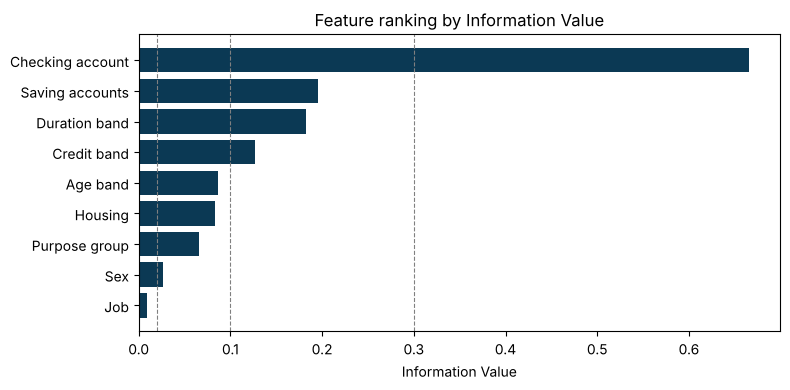

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(iv_table['Feature'][::-1], iv_table['IV'][::-1], color='#0B3954')
for x in [0.02, 0.1, 0.3]:
    ax.axvline(x, color='grey', linestyle='--', linewidth=0.8)
ax.set_xlabel('Information Value')
ax.set_title('Feature ranking by Information Value')
plt.tight_layout()
plt.show()

## 6. Logistic regression: all features together
The tests above look at one feature at a time. A logistic regression looks at all features **together**,
so we can see which ones still matter after the others are taken into account.

**Odds ratio (OR):** above 1 = higher risk than the reference group, below 1 = lower risk.
For Duration and Age the OR is per extra month or year. Credit amount is log-transformed because it is very skewed.

Reference groups: checking `missing`, savings `missing`, housing `own`, sex `male`, purpose `car`, job `2` (skilled).

In [13]:
model_df = df.rename(columns=lambda c: c.replace(' ', '_'))
model_df['log_credit'] = np.log(model_df['Credit_amount'])

formula = ("bad ~ C(Checking_account, Treatment('missing')) + C(Saving_accounts, Treatment('missing'))"
           " + Duration + log_credit + Age + C(Housing, Treatment('own')) + C(Sex, Treatment('male'))"
           " + C(Purpose_group, Treatment('car')) + C(Job, Treatment('2'))")

model = smf.logit(formula, data=model_df).fit(disp=0)

odds = pd.DataFrame({
    'Odds ratio': np.exp(model.params),
    '95% CI low': np.exp(model.conf_int()[0]),
    '95% CI high': np.exp(model.conf_int()[1]),
    'p-value': model.pvalues,
}).round(3).drop(index='Intercept')

# Shorter row names, e.g. "Checking account: little"
odds.index = (odds.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.", r'\1: ', regex=True)
              .str.replace(']', '', regex=False).str.replace('_', ' '))
odds['Significant'] = np.where(odds['p-value'] < 0.05, 'Yes', 'No')
odds

,Odds ratio,95% CI low,95% CI high,p-value,Significant
Checking account: little,6.039,3.974,9.177,0.000,Yes
Checking account: moderate,4.139,2.727,6.282,0.000,Yes
Checking account: rich,2.301,1.141,4.638,0.020,Yes
Saving accounts: little,2.272,1.428,3.616,0.001,Yes
Saving accounts: moderate,1.935,1.034,3.621,0.039,Yes
Saving accounts: quite rich,1.535,0.675,3.489,0.307,No
Saving accounts: rich,0.763,0.283,2.061,0.594,No
Housing: free,1.328,0.789,2.235,0.285,No
Housing: rent,1.419,0.950,2.121,0.088,No
Sex: female,1.448,1.032,2.032,0.032,Yes


In [14]:
print('Number of customers :', int(model.nobs))
print('Pseudo R-squared    :', round(model.prsquared, 3))
print('Model p-value (LLR) :', f'{model.llr_pvalue:.2e}')
print('Converged           :', model.mle_retvals['converged'])

Number of customers : 1000
Pseudo R-squared    : 0.174
Model p-value (LLR) : 9.70e-34
Converged           : True


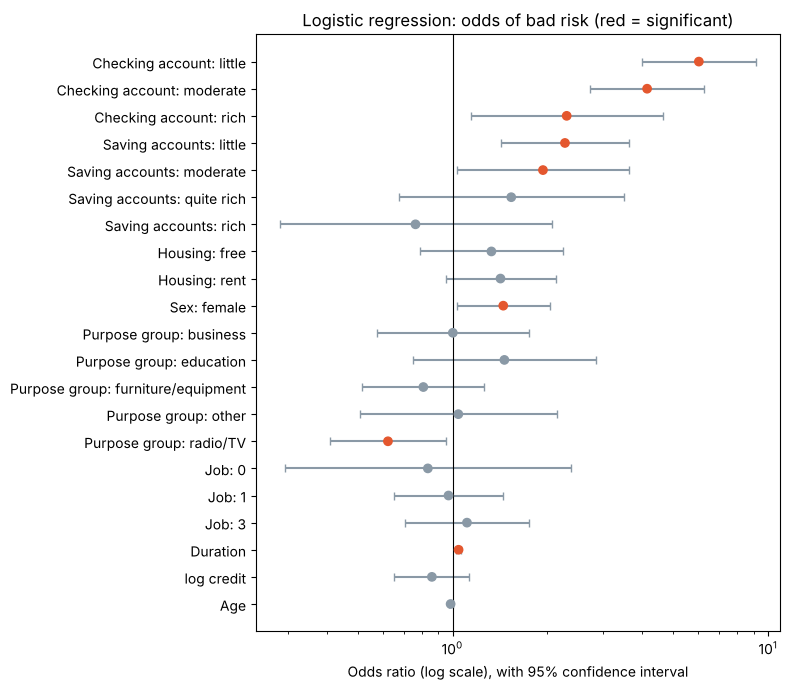

In [15]:
fig, ax = plt.subplots(figsize=(8, 7))
o = odds.iloc[::-1]
colors = ['#E4572E' if s == 'Yes' else '#8A99A6' for s in o['Significant']]
ax.errorbar(o['Odds ratio'], range(len(o)),
            xerr=[o['Odds ratio'] - o['95% CI low'], o['95% CI high'] - o['Odds ratio']],
            fmt='none', ecolor='#8A99A6', capsize=3)
ax.scatter(o['Odds ratio'], range(len(o)), color=colors, zorder=3)
ax.axvline(1, color='black', linewidth=0.8)
ax.set_yticks(range(len(o)))
ax.set_yticklabels(o.index)
ax.set_xscale('log')
ax.set_xlabel('Odds ratio (log scale), with 95% confidence interval')
ax.set_title('Logistic regression: odds of bad risk (red = significant)')
plt.tight_layout()
plt.show()

### 6.1 Is the higher risk for women explained by other features?

In [16]:
sex_only = smf.logit("bad ~ C(Sex, Treatment('male'))", data=model_df).fit(disp=0)
key = "C(Sex, Treatment('male'))[T.female]"
print('Women vs men, Sex only        : OR =', round(np.exp(sex_only.params[key]), 2), ' p =', round(sex_only.pvalues[key], 3))
print('Women vs men, all features    : OR =', round(np.exp(model.params[key]), 2), ' p =', round(model.pvalues[key], 3))

Women vs men, Sex only        : OR = 1.42  p = 0.017
Women vs men, all features    : OR = 1.45  p = 0.032


The difference for women remains after accounting for the other features (OR about 1.45, p = 0.032).
**Note:** sex is a protected characteristic. Using it to decide on credit is restricted or illegal in many countries,
so it should be reviewed before being used in a model, even though it is statistically related to risk here.

### 6.2 Does the effect of credit amount depend on duration?

In [17]:
with_interaction = smf.logit(formula + ' + log_credit:Duration', data=model_df).fit(disp=0)
lr_stat = 2 * (with_interaction.llf - model.llf)
lr_p = stats.chi2.sf(lr_stat, 1)
print('Interaction odds ratio :', round(np.exp(with_interaction.params['log_credit:Duration']), 3))
print('Likelihood-ratio test  : chi-square =', round(lr_stat, 2), ' p =', round(lr_p, 3))

Interaction odds ratio : 0.987
Likelihood-ratio test  : chi-square = 2.33  p = 0.127


The interaction is **not** significant (p = 0.127), so the simpler model without it is kept.

### 6.3 How well do these features separate good and bad customers?
ROC-AUC measures how well the model ranks bad customers above good ones (0.5 = guessing, 1.0 = perfect).
5-fold cross-validation scores each customer with a model that **did not** see that customer, which gives an honest estimate.

In [18]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_auc = []
for train_idx, test_idx in folds.split(model_df, model_df['bad']):
    train, test = model_df.iloc[train_idx], model_df.iloc[test_idx]
    fold_model = smf.logit(formula, data=train).fit(disp=0)
    fold_auc.append(roc_auc_score(test['bad'], fold_model.predict(test)))

print('ROC-AUC on the training data :', round(roc_auc_score(model_df['bad'], model.predict(model_df)), 3))
print('ROC-AUC, 5-fold cross-valid. :', round(np.mean(fold_auc), 3), '+/-', round(np.std(fold_auc), 3))

ROC-AUC on the training data : 0.776
ROC-AUC, 5-fold cross-valid. : 0.744 +/- 0.021


## 7. Answers to the statistical questions

In [19]:
p = all_tests.set_index('Feature')['p-value']
answers = pd.DataFrame([
    ['1', 'Is checking account status associated with risk?', f"Yes, strongly (p = {p['Checking account']:.1e}, V = 0.35)"],
    ['2', 'Is savings level associated with risk; does risk fall as savings rise?', f"Yes (p = {p['Saving accounts']:.1e}); falling trend confirmed (p = {trend.loc[0, 'p-value']:.1e})"],
    ['3', 'Do bad-risk customers borrow larger amounts?', f"Yes, but weakly (p = {p['Credit amount']:.3f}); not significant once duration is included"],
    ['4', 'Do bad-risk customers have longer loans?', f"Yes (p = {p['Duration']:.1e}); each extra month raises the odds by about 4.5%"],
    ['5', 'Are younger customers more likely to be bad risk?', f"Yes (p = {p['Age']:.1e}); mainly ages 19 to 25"],
    ['6', 'Does housing type affect risk?', f"Yes, weakly (p = {p['Housing']:.1e}); not significant once other features are included"],
    ['7', 'Is the higher bad rate for women still present after adjusting?', 'Yes (OR 1.45, p = 0.032), but not significant on its own after Holm correction'],
    ['8', 'Does purpose affect risk once small groups are combined?', f"Borderline (p = {p['Purpose group']:.3f}); not significant after Holm correction"],
    ['9', 'Do missing account values carry information?', 'Yes, for both accounts (p < 0.001); missing means lower risk'],
    ['10', 'Does the credit amount effect depend on duration?', f'No (p = {lr_p:.3f})'],
], columns=['No.', 'Question', 'Answer'])
answers

,No.,Question,Answer
0,1,Is checking account status associated with risk?,"Yes, strongly (p = 1.2e-26, V = 0.35)"
1,2,Is savings level associated with risk; does risk fall as savings rise?,Yes (p = 2.8e-07); falling trend confirmed (p = 3.4e-05)
2,3,Do bad-risk customers borrow larger amounts?,"Yes, but weakly (p = 0.006); not significant once duration is included"
3,4,Do bad-risk customers have longer loans?,Yes (p = 8.0e-11); each extra month raises the odds by about 4.5%
4,5,Are younger customers more likely to be bad risk?,Yes (p = 3.9e-04); mainly ages 19 to 25
5,6,Does housing type affect risk?,"Yes, weakly (p = 1.1e-04); not significant once other features are included"
6,7,Is the higher bad rate for women still present after adjusting?,"Yes (OR 1.45, p = 0.032), but not significant on its own after Holm correction"
7,8,Does purpose affect risk once small groups are combined?,Borderline (p = 0.020); not significant after Holm correction
8,9,Do missing account values carry information?,"Yes, for both accounts (p < 0.001); missing means lower risk"
9,10,Does the credit amount effect depend on duration?,No (p = 0.127)


## 8. Quick checks

In [20]:
checks = {
    'Dataset has 1,000 customers': len(df) == 1000,
    'Bad rate is 30%': df['bad'].mean() == 0.30,
    'Every crosstab adds up to 1,000': all(pd.crosstab(df[c], df['Risk']).values.sum() == 1000 for c in cat_features),
    'All chi-square expected counts are at least 5': cat_results['Cells with expected < 5'].sum() == 0,
    'All p-values are between 0 and 1': all_tests['p-value'].between(0, 1).all(),
    'Holm p-values are never smaller than raw p-values': (all_tests['Holm p-value'] >= all_tests['p-value']).all(),
    'Logistic regression converged on 1,000 customers': model.mle_retvals['converged'] and int(model.nobs) == 1000,
    'Cross-validated AUC is better than guessing': np.mean(fold_auc) > 0.5,
    'Checking account has the highest Information Value': iv_table.loc[0, 'Feature'] == 'Checking account',
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Dataset has 1,000 customers
PASS - Bad rate is 30%
PASS - Every crosstab adds up to 1,000
PASS - All chi-square expected counts are at least 5
PASS - All p-values are between 0 and 1
PASS - Holm p-values are never smaller than raw p-values
PASS - Logistic regression converged on 1,000 customers
PASS - Cross-validated AUC is better than guessing
PASS - Checking account has the highest Information Value

All 9 checks passed


## 9. Summary

1. **Checking account** is the strongest single feature (Cramer's V 0.35, IV 0.67). Customers with a "little" balance have about **6 times the odds** of bad risk compared with customers with no recorded account, after allowing for all other features.
2. **Duration** is the strongest numerical feature. Risk rises steadily with loan length, and each extra month raises the odds of bad risk by about 4.5%.
3. **Saving accounts** matter: risk falls as savings rise, and a "little" balance more than doubles the odds compared with no recorded account.
4. **Credit amount, Age and Housing** are related to risk on their own, but they lose significance in the full model, mainly because they overlap with Duration and the account features.
5. **Purpose and Sex** are borderline. **Job** shows no relationship with risk.
6. Together the features give a cross-validated ROC-AUC of about 0.75, a reasonable starting point for a credit-risk model.